# 📌 **Hands-on 3: Perceptrón Multicapa (MLP) con Scikit-Learn**
**Asignatura:** Deep Learning 2026B  
**Objetivo:** Crear un pipeline completo de Machine Learning para clasificar el dataset **Iris** utilizando la librería `scikit-learn`.

## **1. Fundamentos Teóricos y Modelo Matemático**
Un **Perceptrón Multicapa (MLP)** es una red neuronal artificial *feedforward* compuesta por:
- **Capa de Entrada (Input Layer):** Recibe las características (features) del dataset.
- **Capas Ocultas (Hidden Layers):** Realizan transformaciones no lineales mediante combinaciones ponderadas y funciones de activación.
- **Capa de Salida (Output Layer):** Produce la probabilidad o etiqueta de la clase predicha.

### **Ecuaciones Operativas:**
1. **Combinación Lineal:** $z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)}$
2. **Activación No Lineal (ej. ReLU):** $a^{(l)} = \max(0, z^{(l)})$
3. **Función de Pérdida (Cross-Entropy):** $\mathcal{L}(y, \hat{y}) = -\sum_{c=1}^{C} y_c \log(\hat{y}_c)$

In [6]:
# Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Librerías cargadas exitosamente.")

Librerías cargadas exitosamente.


## **2. Carga de Datos y Visualización (Scatter Plot)**

Dimensiones de X: (150, 4)
Clases a clasificar: ['setosa' 'versicolor' 'virginica']


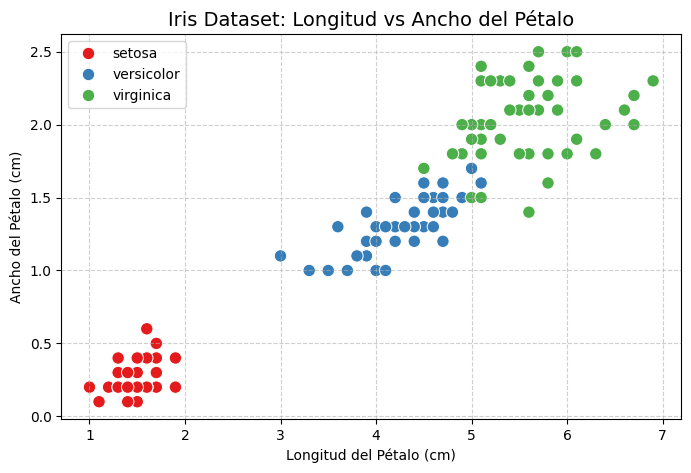

In [7]:
# Cargar el dataset Iris
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print(f"Dimensiones de X: {X.shape}")
print(f"Clases a clasificar: {target_names}")

# Visualización: Scatter Plot de las características del pétalo
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X[:, 2], y=X[:, 3], hue=target_names[y], palette="Set1", s=80)
plt.title("Iris Dataset: Longitud vs Ancho del Pétalo", fontsize=14)
plt.xlabel("Longitud del Pétalo (cm)")
plt.ylabel("Ancho del Pétalo (cm)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## **3. Preprocesamiento: Splitting y Scaling**

In [8]:
# Divisón de los datos (80% Entrenamiento, 20% Prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Escalamiento de características (Estandarización: media=0, var=1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Tamaño de entrenamiento: {X_train_scaled.shape[0]} muestras")
print(f"Tamaño de prueba: {X_test_scaled.shape[0]} muestras")

Tamaño de entrenamiento: 120 muestras
Tamaño de prueba: 30 muestras


## **4. Configuración y Entrenamiento del MLPClassifier**

In [9]:
# Instanciar el modelo con 2 capas ocultas de 10 neuronas cada una
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

# Entrenamiento mediante Backpropagation
mlp.fit(X_train_scaled, y_train)
print(f"Entrenamiento completado en {mlp.n_iter_} iteraciones.")

Entrenamiento completado en 603 iteraciones.


## **5. Evaluación del Modelo**

🎯 Exactitud (Accuracy): 96.67%


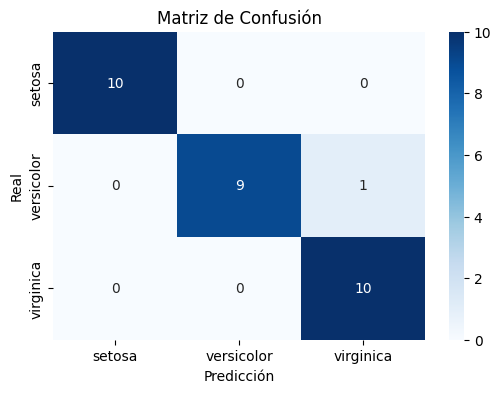


--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [10]:
# Predicciones sobre el conjunto de test
y_pred = mlp.predict(X_test_scaled)

# Cálculo de métricas
acc = accuracy_score(y_test, y_pred)
print(f"🎯 Exactitud (Accuracy): {acc * 100:.2f}%")

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title("Matriz de Confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

# Reporte de clasificación
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred, target_names=target_names))